In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
conn = sqlite3.connect("language.db")
df   = pd.read_sql("select id, project, text, language from dataset", conn).set_index(['id'])

## Description du corpus

Il y a 419 textes en tout et ceux-ci sont de deux types: lettre se sentence ou lettre de pardon. Les lettres sont écrites soit en francais, soit en néérlandais. 

Il y a 372 lettres écrites en néérlandais, et 47 qui sont écrites en francais. Il n'y a que 3 lettres de sentences dans le corpus, tout le reste étant des lettres de pardon. Toutes les lettres de sentence sont écrites en néérlandais, et 47 lettres de pardon sont écrites en francais. 

Les lettres de sentences obtenues sont donc plus rares, mais elles sont en général **beaucoup** plus longues (environ 10x plus longues) que les lettres de pardon. 

Les lettres de pardon font en moyenne 1125 mots (+/- 310 mots). Si on compte environ 400 mots / page (ce qui est a peu pres standard pour une page A4 en taille 12); cela veut dire que les textes font entre deux et 4 pages (3 pages dans la majorité des cas).


### Ventilation par langue

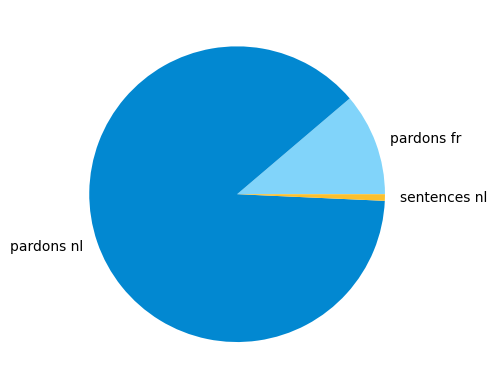

In [20]:
data   = df.groupby(['project', 'language']).count()
labels = data.index.map(lambda xs: ' '.join(xs))

plt.pie(
    data['text'], 
    labels=labels, 
    #autopct='%1.2f%%', 
    colors=["#81D4FA", "#0288D1", "#FBC02D"],
    #pctdistance=1.2,
    #labeldistance=1.4
)
plt.show()

## Taille des textes

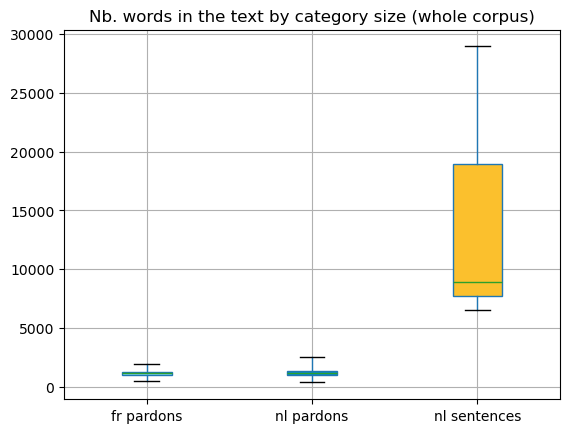

nb_words                                              \
                      count          mean           std     min     25%   
language project                                                          
fr       pardons       47.0   1145.872340    309.626256   454.0   952.0   
nl       pardons      369.0   1152.674797    308.325831   356.0   978.0   
         sentences      3.0  14787.666667  12332.306448  6508.0  7701.0   

                                              
                       50%      75%      max  
language project                              
fr       pardons    1122.0   1250.5   1957.0  
nl       pardons    1129.0   1301.0   2565.0  
         sentences  8894.0  18927.5  28961.0

In [62]:
df['nb_words'] = df.apply(lambda x: len(x.text.split()), axis=1)
data   = df[['language', 'project', 'nb_words']].groupby(['language', 'project'])
labels = data.count().index.map(lambda xs: ' '.join(xs))

colors =["#81D4FA", "#0288D1", "#FBC02D"]
ax,bplot  = data.boxplot(
    whis=(0, 100), 
    subplots=False,
    patch_artist=True,
    return_type='both',
)

for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title("Nb. words in the text by category size (whole corpus)")
ax.set_xticklabels(labels)
plt.show()

data.describe()

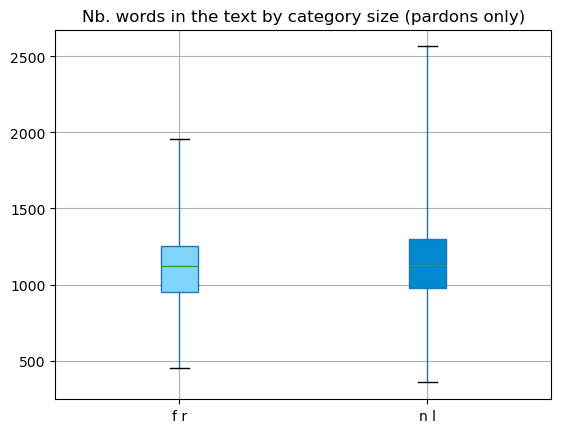

nb_words                                                         \
            count         mean         std    min    25%     50%     75%   
language                                                                   
fr           47.0  1145.872340  309.626256  454.0  952.0  1122.0  1250.5   
nl          369.0  1152.674797  308.325831  356.0  978.0  1129.0  1301.0   

                  
             max  
language          
fr        1957.0  
nl        2565.0

In [63]:
df['nb_words'] = df.apply(lambda x: len(x.text.split()), axis=1)
data   = df[df['project']=='pardons'][['language', 'nb_words']].groupby(['language'])
labels = data.count().index.map(lambda xs: ' '.join(xs))

colors =["#81D4FA", "#0288D1", "#FBC02D"]
ax,bplot  = data.boxplot(
    whis=(0, 100), 
    subplots=False,
    patch_artist=True,
    return_type='both',
)

for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title("Nb. words in the text by category size (pardons only)")
ax.set_xticklabels(labels)
plt.show()

data.describe()